# Face recognition: comparison of five trained models

This notebook analyzes the **committed numeric snapshot** of the completed experiment. Its saved outputs are visible without the face dataset. Rerunning it validates the test metrics against the saved predictions and regenerates English plots; it does not retrain models or update the snapshot from a new training run.

There are 398 training sources, 100 held-out test sources, and ten identities. Every identity contributes ten test images. Both preprocessing families use the same source membership. See [REPORT.md](REPORT.md) for the full protocol and limitations.

In [1]:
from pathlib import Path
import sys, io
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

base = Path.cwd()
if not (base / "analyse_resultat.py").exists():
    base = base / "analyse"
sys.path.insert(0, str(base.resolve()))
import analyse_resultat as report

def show(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

scores, predictions = report.load_snapshot()
print("Validated five models against the shared 100-image reference test split.")
print("Saved snapshot: 398 training images, 100 test images, 10 identities.")


Validated five models against the shared 100-image reference test split.
Saved snapshot: 398 training images, 100 test images, 10 identities.


## Metrics for every model

Precision, recall, and F1 use macro averaging. Test classes have equal support, so macro recall equals accuracy. CV F1 is the best parameter-search score on training folds; it is not a nested-CV estimate.

,model_name,accuracy_train,f1_train,f1_cv,std_f1_cv,accuracy_test,precision_test,recall_test,f1_test,correct,errors
0,FaceNet + linear SVM,1.0,1.0,0.9296,0.0136,0.95,0.9518,0.95,0.9499,95,5
1,FaceNet + RBF SVM,1.0,1.0,0.9371,0.0161,0.95,0.9518,0.95,0.9499,95,5
2,FaceNet + kNN,1.0,1.0,0.9108,0.0281,0.93,0.9359,0.93,0.9302,93,7
3,PCA + linear SVM,1.0,1.0,0.8426,0.0243,0.96,0.9642,0.96,0.9598,96,4
4,PCA + RBF SVM,1.0,1.0,0.8799,0.0171,0.97,0.9727,0.97,0.9693,97,3


,model_name,params,grid_candidates,search_seconds
0,FaceNet + linear SVM,"{""svc__C"": 10}",4,0.270238
1,FaceNet + RBF SVM,"{""svc__C"": 10, ""svc__gamma"": ""scale""}",9,0.895711
2,FaceNet + kNN,"{""kneighborsclassifier__n_neighbors"": 7, ""knei...",8,0.368710
3,PCA + linear SVM,"{""pca__n_components"": 150, ""pca__whiten"": true...",24,6.903117
4,PCA + RBF SVM,"{""pca__n_components"": 150, ""pca__whiten"": true...",72,11.005957


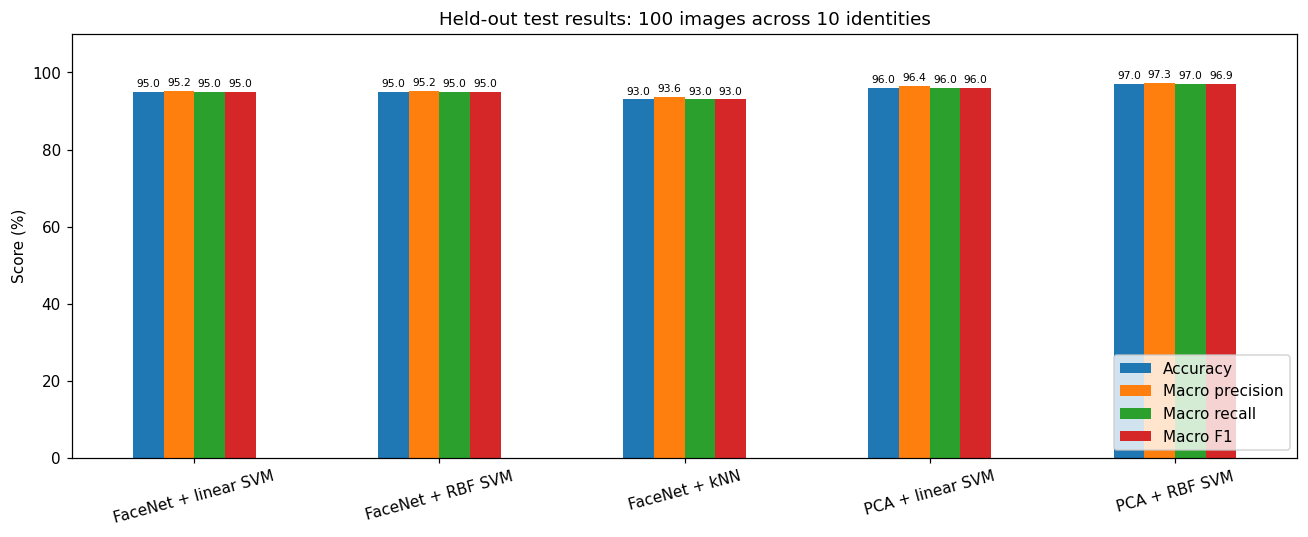

In [2]:
columns = ["model_name", "accuracy_train", "f1_train", "f1_cv", "std_f1_cv", "accuracy_test", "precision_test", "recall_test", "f1_test", "correct", "errors"]
display(scores[columns].round(4))
display(scores[["model_name", "params", "grid_candidates", "search_seconds"]])
show(report.test_plot(scores))


## Train, validation, test, and uncertainty

The 100% training scores show strong in-sample fits. PCA has larger train-to-CV gaps, suggesting more variance. kNN's training score includes the self-neighbor effect and needs particular care. The Wilson accuracy intervals are wide and overlap. The test split is too small to establish a winner from a few additional correct predictions.

,model_name,f1_train,f1_cv,f1_test,ci95_low,ci95_high,train_CV_gap_points
0,FaceNet + linear SVM,1.0,0.9296,0.9499,0.8882,0.9785,7.0357
1,FaceNet + RBF SVM,1.0,0.9371,0.9499,0.8882,0.9785,6.2945
2,FaceNet + kNN,1.0,0.9108,0.9302,0.8625,0.9657,8.9246
3,PCA + linear SVM,1.0,0.8426,0.9598,0.9016,0.9843,15.7402
4,PCA + RBF SVM,1.0,0.8799,0.9693,0.9155,0.9897,12.0149


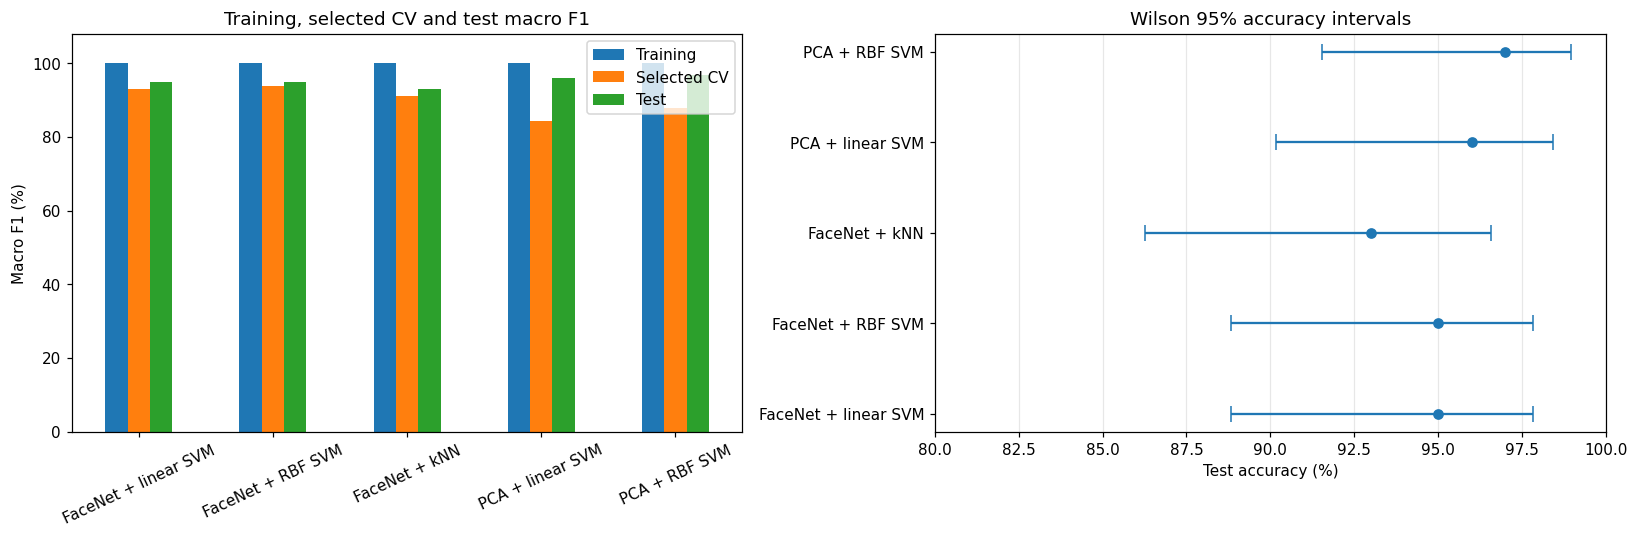

In [3]:
gaps = scores[["model_name", "f1_train", "f1_cv", "f1_test", "ci95_low", "ci95_high"]].copy()
gaps["train_CV_gap_points"] = 100 * (gaps.f1_train - gaps.f1_cv)
display(gaps.round(4))
show(report.generalization_plot(scores))


## Learning curves

These curves come from five grouped training folds at four target training sizes, using the already-selected parameters. Lines show mean macro F1; shaded areas show one fold standard deviation. They help inspect learning behavior but are not independent validation of the parameter search.

,model_id,train_size_target,train_mean,train_std,validation_mean,validation_std
0,svm_linear,160,1.0,0.0,0.9202,0.0131
1,svm_linear,220,1.0,0.0,0.9138,0.0130
2,svm_linear,270,1.0,0.0,0.9252,0.0139
3,svm_linear,317,1.0,0.0,0.9295,0.0135
4,svm_rbf,160,1.0,0.0,0.9207,0.0225
5,svm_rbf,220,1.0,0.0,0.9163,0.0217
6,svm_rbf,270,1.0,0.0,0.9244,0.0250
7,svm_rbf,317,1.0,0.0,0.9369,0.0160
8,knn,160,1.0,0.0,0.8880,0.0183
9,knn,220,1.0,0.0,0.9081,0.0346


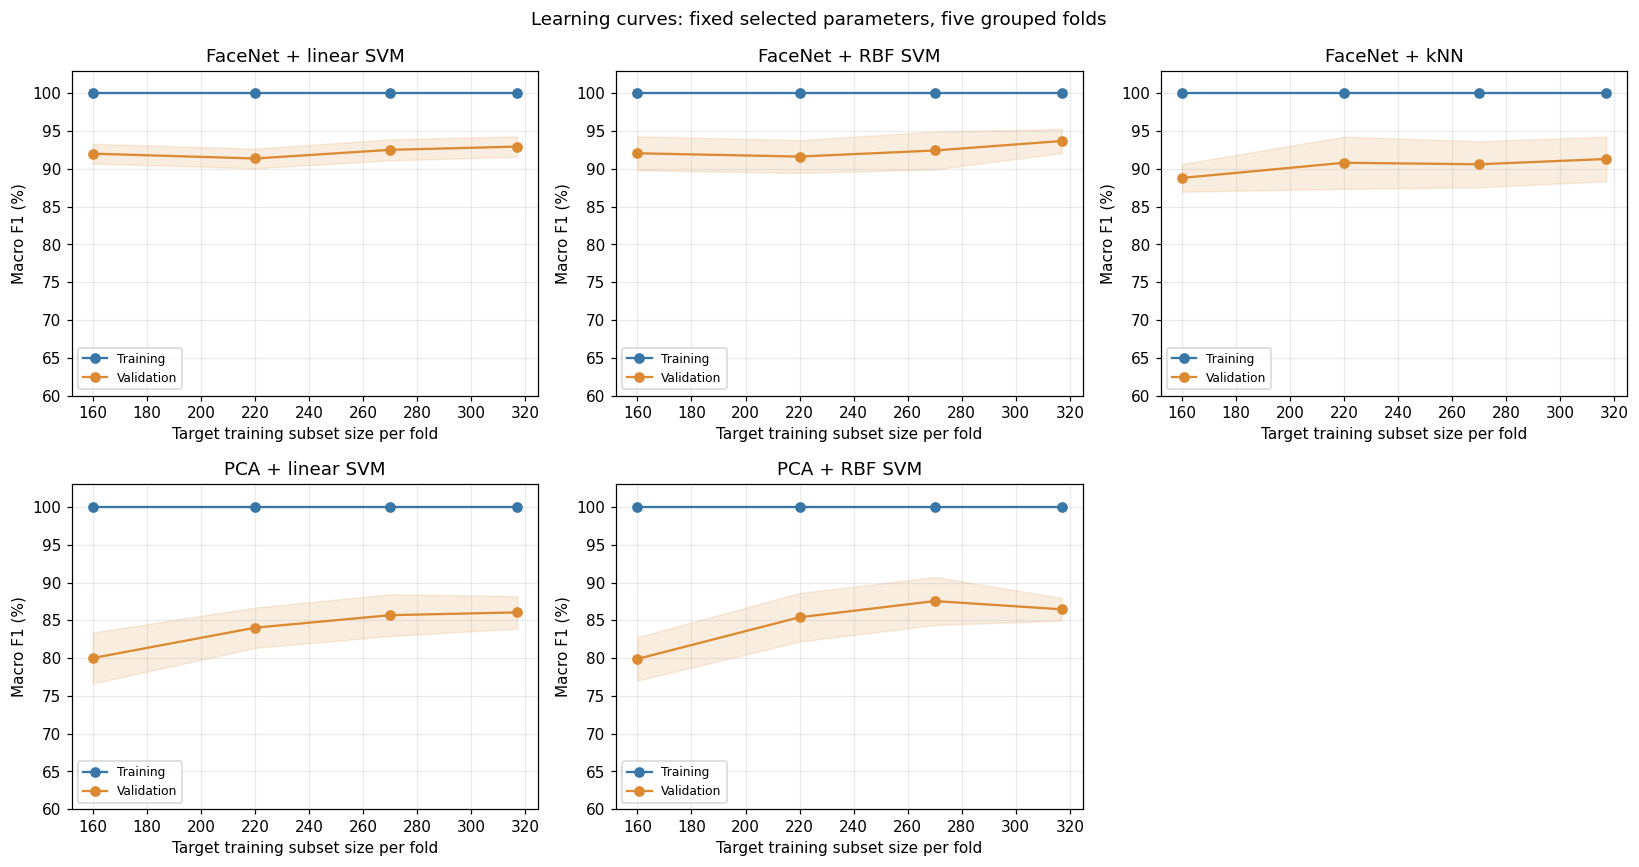

In [4]:
display(pd.read_csv(report.RESULTS / "learning_curves.csv").round(4))
show(report.learning_plot())


## Results on the ten test images of each identity

Each cell below gives correct predictions out of ten. Inspect the per-identity metrics and confusion matrices to identify repeated weaknesses. A single mistake changes that identity's recall by ten percentage points.

,FaceNet + linear SVM,FaceNet + RBF SVM,FaceNet + kNN,PCA + linear SVM,PCA + RBF SVM
class,,,,,
Ariel_Sharon,10,10,10,10,10
Colin_Powell,10,10,10,10,10
Donald_Rumsfeld,8,8,8,9,9
George_W_Bush,10,10,10,10,10
Gerhard_Schroeder,10,10,9,8,8
Hugo_Chavez,9,9,10,9,10
Jean_Chretien,9,9,8,10,10
John_Ashcroft,10,10,10,10,10
Junichiro_Koizumi,10,10,10,10,10


,model_id,class,precision,recall,f1-score,support,correct
0,svm_linear,Ariel_Sharon,0.9091,1.0,0.9524,10.0,10
1,svm_linear,Colin_Powell,1.0000,1.0,1.0000,10.0,10
2,svm_linear,Donald_Rumsfeld,0.8000,0.8,0.8000,10.0,8
3,svm_linear,George_W_Bush,1.0000,1.0,1.0000,10.0,10
4,svm_linear,Gerhard_Schroeder,1.0000,1.0,1.0000,10.0,10
5,svm_linear,Hugo_Chavez,1.0000,0.9,0.9474,10.0,9
6,svm_linear,Jean_Chretien,0.9000,0.9,0.9000,10.0,9
7,svm_linear,John_Ashcroft,0.9091,1.0,0.9524,10.0,10
8,svm_linear,Junichiro_Koizumi,1.0000,1.0,1.0000,10.0,10
9,svm_linear,Tony_Blair,1.0000,0.9,0.9474,10.0,9


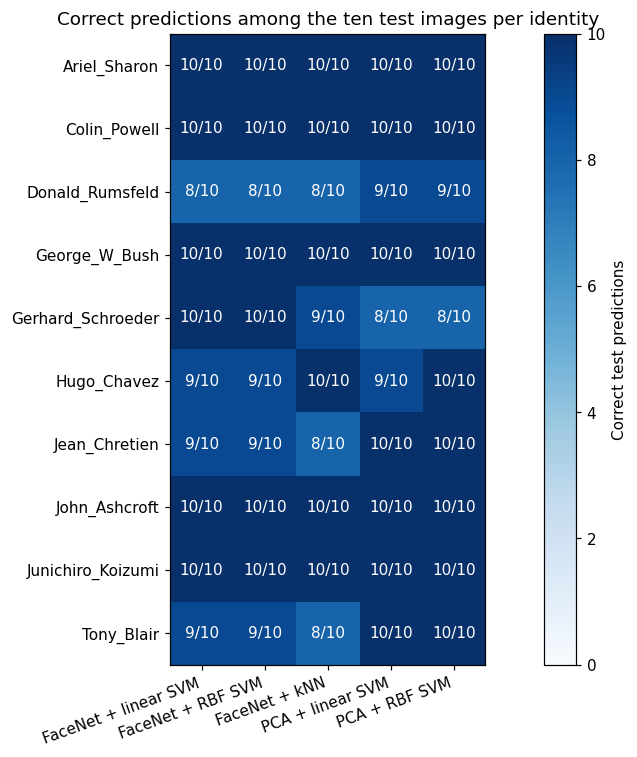

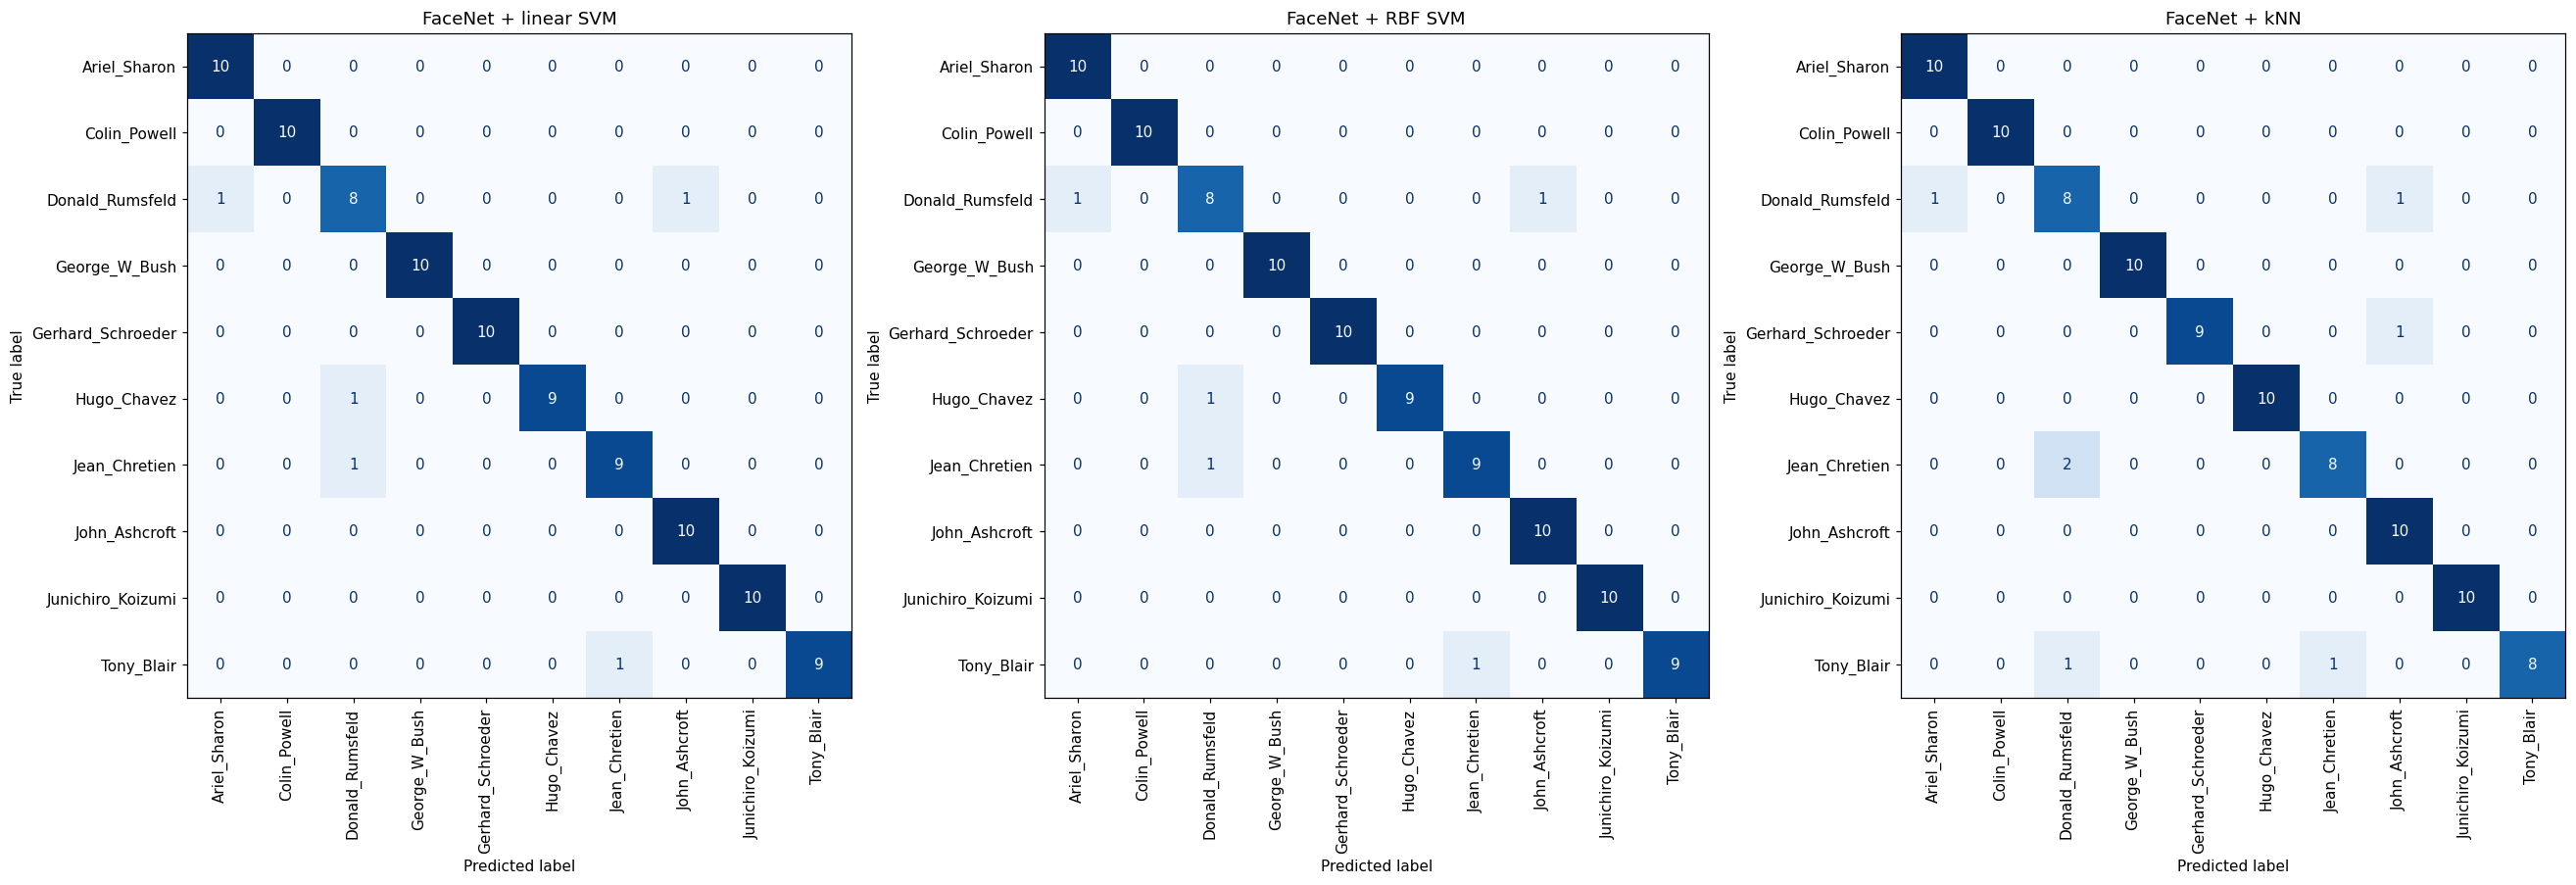

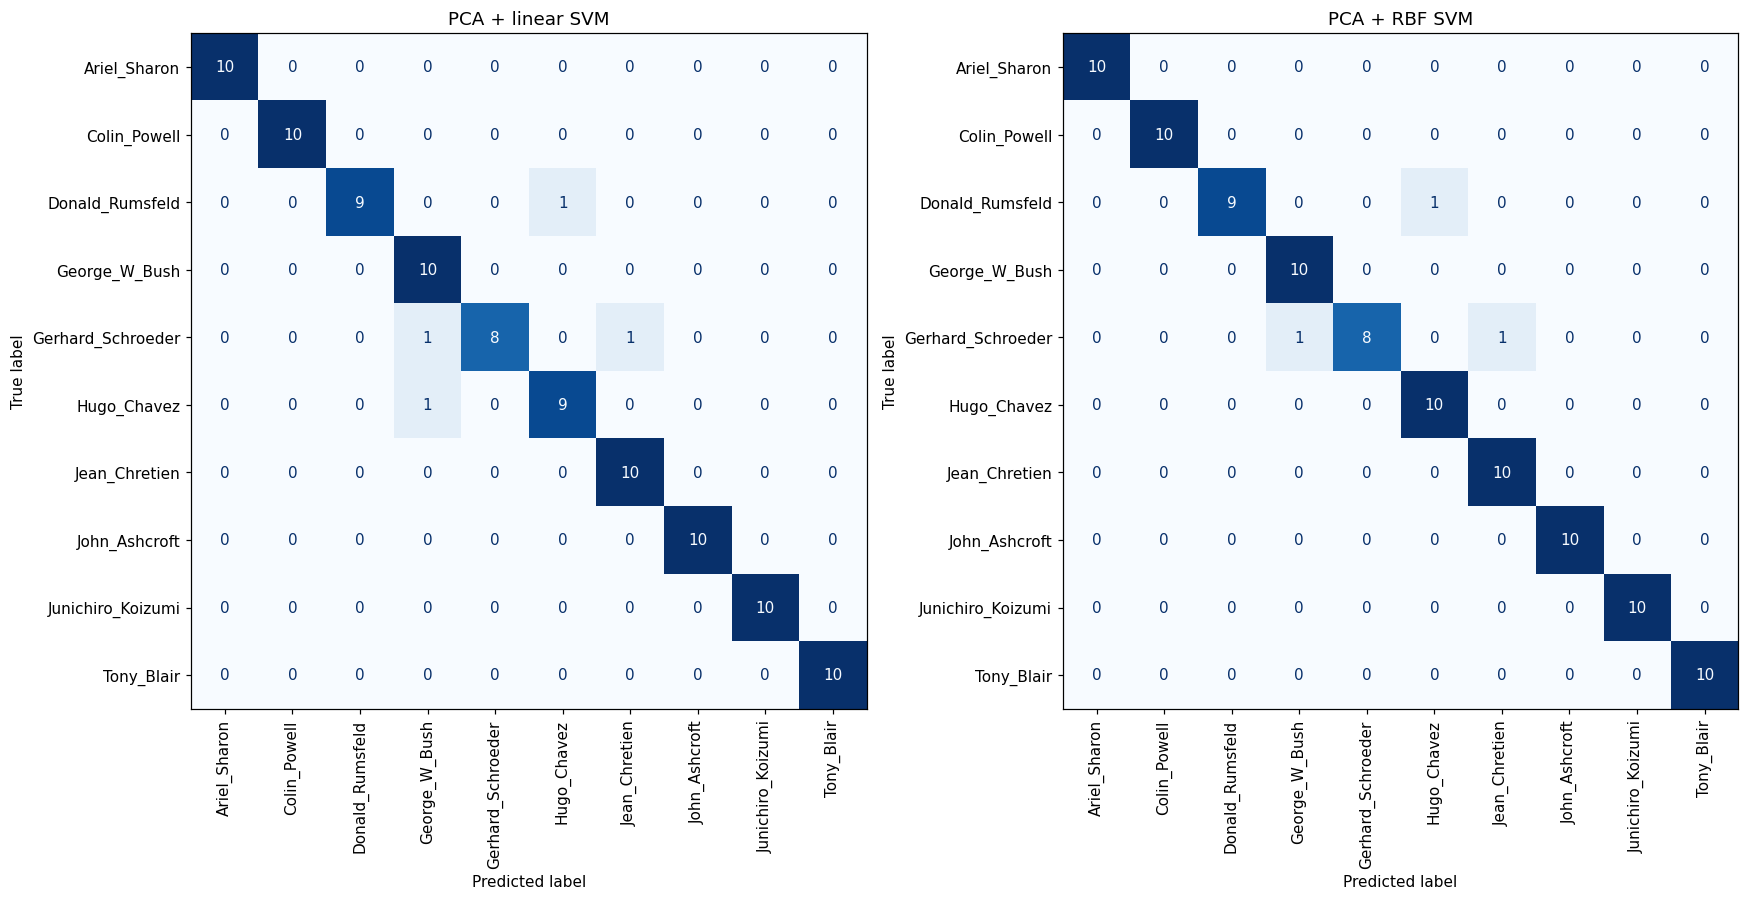

In [5]:
display(pd.read_csv(report.RESULTS / "per_class_correct.csv").set_index("class"))
display(pd.read_csv(report.RESULTS / "per_class_metrics.csv").round(4))
show(report.class_plot())
for fig in report.confusion_plots(predictions):
    show(fig)


## Errors and paired comparisons

The error table lists sources misclassified by at least one model. Columns FL/FR/FK mean FaceNet linear SVM/RBF SVM/kNN; PL/PR mean PCA linear/RBF SVM. The FaceNet SVMs have identical predictions in this run.

Exact paired McNemar tests compare each pair's disagreements on the same test sources. Holm correction accounts for ten comparisons. No pair is significant at 5%; that does not prove model equivalence.

In [6]:
display(pd.read_csv(report.RESULTS / "errors_by_image.csv"))
paired = report.paired_comparisons(predictions)
saved = pd.read_csv(report.RESULTS / "paired_model_comparisons.csv")
import numpy as np
assert np.allclose(paired.p_exact, saved.p_exact)
assert np.allclose(paired.p_holm, saved.p_holm)
display(paired)
print(f"Significant paired differences after correction: {int(paired.significant_5pct.sum())}/10")


Significant paired differences after correction: 0/10


,source,image_path,class,FL,error_FL,FR,error_FR,FK,error_FK,PL,error_PL,PR,error_PR,error_count
0,Donald_Rumsfeld/Donald_Rumsfeld_0005.jpg,test/Donald_Rumsfeld/Donald_Rumsfeld_0005.jpg.png,Donald_Rumsfeld,Ariel_Sharon,True,Ariel_Sharon,True,Ariel_Sharon,True,Hugo_Chavez,True,Hugo_Chavez,True,5
1,Donald_Rumsfeld/Donald_Rumsfeld_0028.jpg,test/Donald_Rumsfeld/Donald_Rumsfeld_0028.jpg.png,Donald_Rumsfeld,John_Ashcroft,True,John_Ashcroft,True,John_Ashcroft,True,Donald_Rumsfeld,False,Donald_Rumsfeld,False,3
2,Jean_Chretien/Jean_Chretien_0038.jpg,test/Jean_Chretien/Jean_Chretien_0038.jpg.png,Jean_Chretien,Donald_Rumsfeld,True,Donald_Rumsfeld,True,Donald_Rumsfeld,True,Jean_Chretien,False,Jean_Chretien,False,3
3,Tony_Blair/Tony_Blair_0031.jpg,test/Tony_Blair/Tony_Blair_0031.jpg.png,Tony_Blair,Jean_Chretien,True,Jean_Chretien,True,Jean_Chretien,True,Tony_Blair,False,Tony_Blair,False,3
4,Gerhard_Schroeder/Gerhard_Schroeder_0026.jpg,test/Gerhard_Schroeder/Gerhard_Schroeder_0026....,Gerhard_Schroeder,Gerhard_Schroeder,False,Gerhard_Schroeder,False,Gerhard_Schroeder,False,George_W_Bush,True,George_W_Bush,True,2
5,Gerhard_Schroeder/Gerhard_Schroeder_0032.jpg,test/Gerhard_Schroeder/Gerhard_Schroeder_0032....,Gerhard_Schroeder,Gerhard_Schroeder,False,Gerhard_Schroeder,False,Gerhard_Schroeder,False,Jean_Chretien,True,Jean_Chretien,True,2
6,Hugo_Chavez/Hugo_Chavez_0001.jpg,test/Hugo_Chavez/Hugo_Chavez_0001.jpg.png,Hugo_Chavez,Donald_Rumsfeld,True,Donald_Rumsfeld,True,Hugo_Chavez,False,Hugo_Chavez,False,Hugo_Chavez,False,2
7,Gerhard_Schroeder/Gerhard_Schroeder_0001.jpg,test/Gerhard_Schroeder/Gerhard_Schroeder_0001....,Gerhard_Schroeder,Gerhard_Schroeder,False,Gerhard_Schroeder,False,John_Ashcroft,True,Gerhard_Schroeder,False,Gerhard_Schroeder,False,1
8,Hugo_Chavez/Hugo_Chavez_0002.jpg,test/Hugo_Chavez/Hugo_Chavez_0002.jpg.png,Hugo_Chavez,Hugo_Chavez,False,Hugo_Chavez,False,Hugo_Chavez,False,George_W_Bush,True,Hugo_Chavez,False,1
9,Jean_Chretien/Jean_Chretien_0030.jpg,test/Jean_Chretien/Jean_Chretien_0030.jpg.png,Jean_Chretien,Jean_Chretien,False,Jean_Chretien,False,Donald_Rumsfeld,True,Jean_Chretien,False,Jean_Chretien,False,1


,A,B,A_correct_B_wrong,B_correct_A_wrong,discordant,p_exact,p_holm,significant_5pct
0,FaceNet + linear SVM,FaceNet + RBF SVM,0,0,0,1.000000,1.0,False
1,FaceNet + linear SVM,FaceNet + kNN,3,1,4,0.625000,1.0,False
2,FaceNet + linear SVM,PCA + linear SVM,3,4,7,1.000000,1.0,False
3,FaceNet + linear SVM,PCA + RBF SVM,2,4,6,0.687500,1.0,False
4,FaceNet + RBF SVM,FaceNet + kNN,3,1,4,0.625000,1.0,False
5,FaceNet + RBF SVM,PCA + linear SVM,3,4,7,1.000000,1.0,False
6,FaceNet + RBF SVM,PCA + RBF SVM,2,4,6,0.687500,1.0,False
7,FaceNet + kNN,PCA + linear SVM,3,6,9,0.507812,1.0,False
8,FaceNet + kNN,PCA + RBF SVM,2,6,8,0.289062,1.0,False
9,PCA + linear SVM,PCA + RBF SVM,0,1,1,1.000000,1.0,False


## Leakage checks and validation limits

The completed local experiment audited source membership and labels, exact pixel hashes, the prepared PCA pixels, embedding cache signatures, and duplicate groups inside the five CV folds. No checked duplicate crossed train and test. One dHash candidate pair was entirely in training and grouped during CV.

The cell below rechecks membership and recorded hashes from the committed reference manifest. Source images and fitted estimators are deliberately excluded from Git, so this notebook does not claim to revalidate their bytes in a fresh clone. The original audit's stronger integrity checks require those local artifacts.

PCA was fitted inside each fold, and hyperparameters were selected using training data. There was no nested cross-validation. Quality decisions were made during earlier exploration, test results have since been inspected repeatedly, and overlap with FaceNet pretraining data is unknown. These limits mean a fresh independent test set is needed for further tuning.

In [7]:
reference = pd.read_csv(report.BASE / "reference_split/split_manifest.csv")
assert reference.source.is_unique
assert reference.groupby("source_pixel_sha256").split.nunique().max() == 1
assert reference.groupby("crop_pixel_sha256").split.nunique().max() == 1
counts = pd.crosstab(reference["class"], reference.split)[["train", "test"]]
assert counts.test.eq(10).all()
display(counts)
near = pd.read_csv(report.BASE / "reference_split/near_duplicate_check.csv")
assert not near.cross_split.any()
display(near)
print("Reference membership and recorded duplicate hashes pass the available checks.")


Reference membership and recorded duplicate hashes pass the available checks.


split,train,test
class,,
Ariel_Sharon,40,10
Colin_Powell,40,10
Donald_Rumsfeld,40,10
George_W_Bush,39,10
Gerhard_Schroeder,40,10
Hugo_Chavez,40,10
Jean_Chretien,40,10
John_Ashcroft,39,10
Junichiro_Koizumi,40,10


,source_a,source_b,distance,split_a,split_b,cross_split
0,George_W_Bush/George_W_Bush_0034.jpg,George_W_Bush/George_W_Bush_0036.jpg,5,train,train,False


## Interpretation and next steps

- **Strong small-sample results:** test accuracy is 93-97% for classification among these ten known identities.
- **Overfitting risk:** PCA has the largest train-to-CV gaps. FaceNet has higher validation F1 and smaller gaps. A perfect kNN training score is partly explained by self-neighbors.
- **Underfitting:** there is no obvious global underfit, but individual identities and new capture conditions can still be difficult.
- **Comparison:** PCA RBF has the best observed test accuracy; FaceNet RBF has the best CV F1. The paired tests do not support a reliable ranking from these 100 test sources.
- **Next work:** inspect recurring errors and face-selection mistakes, add diverse training examples, and collect an independent test set before further tuning. Compare stronger PCA regularization using training validation. Fine-tuning FaceNet needs more varied data and its own validation protocol.

See [the report](REPORT.md) for the full discussion. English PNG figures are saved in `analyse/figures/`. New training outputs remain separate from this published snapshot.